# CGMacros: exploratory data analysis

**Goal:** understand the data well enough to build physics-informed glucose models.

What this notebook covers:
1. Loading and cleaning every participant's file
2. Who the participants are
3. Data coverage and the real sensor sampling rates
4. How much the two glucose sensors (Libre vs Dexcom) agree
5. Glucose patterns by group (time in range, daily rhythm)
6. Meal data quality
7. **Post-meal glucose responses**, the core signal for PINN modeling
8. Activity and glucose
9. Saving cleaned data for the modeling notebooks

Run the cells top to bottom. The notebook only **reads** the raw files; the last section writes cleaned copies into a new `processed/` folder.

## 0. Setup

In [113]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
trapezoid = getattr(np, "trapezoid", None) or np.trapz   # numpy 2 renamed trapz
pd.set_option("display.width", 200)

# This notebook lives in the CGMacros folder, next to bio.csv and the CGMacros-0XX folders
DATA_DIR = Path.cwd()
assert (DATA_DIR / "bio.csv").exists(), f"bio.csv not found in {DATA_DIR}."

# One fixed color per group, used in every chart (validated colorblind-safe palette)
GROUP_ORDER = ["Healthy", "Prediabetes", "T2D"]
GROUP_COLORS = {"Healthy": "#2a78d6", "Prediabetes": "#eb6834", "T2D": "#1baf7a"}
SENSOR_COLORS = {"Dexcom": "#2a78d6", "Libre": "#eb6834"}

plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 2,
    "axes.titleweight": "bold", "axes.titlesize": 12,
})

## 1. Load and clean

The raw files have a few quirks, all fixed here:
- column names with trailing spaces (`Amount Consumed `), and `METs` stored **×10**
- meal labels in mixed case (`breakfast`, `Breakfast`, `snack 1`, `Snacks`)
- an extra index column (`Unnamed: 0`) in some files, and the Libre/Dexcom columns swapped in order in one
- **activity in two formats:** 34 people have `METs`, 11 have Fitbit's 0–3 `Intensity` level instead (sedentary, light, moderate, vigorous). We convert METs to the same 0–3 scale so everyone is comparable.
- small column differences: one file has `Steps` instead of activity calories, two lack `Amount Consumed`, one has an extra `Sugar` column

Groups come from HbA1c using the standard ADA cut-offs: below 5.7% healthy, 5.7–6.4% prediabetes, 6.5% and above type 2 diabetes.

In [115]:
def a1c_group(a1c):
    if a1c >= 6.5: return "T2D"
    if a1c >= 5.7: return "Prediabetes"
    return "Healthy"

bio = pd.read_csv(DATA_DIR / "bio.csv")
bio.columns = [c.strip() for c in bio.columns]
bio = bio.rename(columns={"subject": "sid", "A1c PDL (Lab)": "A1c",
                          "Fasting GLU - PDL (Lab)": "fasting_glucose",
                          "Insulin": "fasting_insulin", "Self-identify": "ethnicity",
                          "Body weight": "weight_lb", "Height": "height_in"})
bio["group"] = bio["A1c"].apply(a1c_group)

MEAL_MAP = {"breakfast": "Breakfast", "lunch": "Lunch", "dinner": "Dinner",
            "snack": "Snack", "snacks": "Snack", "snack 1": "Snack"}

def load_subject(path):
    d = pd.read_csv(path)
    d.columns = [c.strip() for c in d.columns]
    d = d.drop(columns=[c for c in d.columns if c.startswith("Unnamed")])
    d = d.rename(columns={"Libre GL": "libre", "Dexcom GL": "dexcom", "HR": "hr",
                          "Calories (Activity)": "activity_kcal", "METs": "mets",
                          "Meal Type": "meal_type", "Calories": "meal_kcal",
                          "Carbs": "carbs", "Protein": "protein", "Fat": "fat",
                          "Fiber": "fiber", "Amount Consumed": "pct_consumed",
                          "Image path": "image_path"})
    d["timestamp"] = pd.to_datetime(d.pop("Timestamp"))
    # Activity comes in two formats: METs x10 (34 people) or Fitbit's 0-3 Intensity level (11 people).
    # Harmonize to one 0-3 intensity scale for everyone; keep real METs where available.
    if "mets" in d:
        d["mets"] = d["mets"] / 10.0                   # undo the x10 scaling
        d["intensity"] = pd.cut(d["mets"], [-np.inf, 1.5, 3, 6, np.inf], labels=[0, 1, 2, 3], right=False).astype(float)
    else:
        d["mets"] = np.nan
        d["intensity"] = d.pop("Intensity").astype(float)
    d["activity_format"] = "METs" if d["mets"].notna().any() else "Intensity"
    for col in ["activity_kcal", "pct_consumed"]:     # one file has Steps instead; two lack Amount Consumed
        if col not in d: d[col] = np.nan
    d["meal_type"] = d["meal_type"].str.strip().str.lower().map(MEAL_MAP)
    d["sid"] = int(path.stem.split("-")[1])
    return d.sort_values("timestamp").reset_index(drop=True)

files = sorted(DATA_DIR.glob("CGMacros-*/CGMacros-*.csv"))
raw = {}
for f in files:
    d = load_subject(f)
    raw[d["sid"].iloc[0]] = d
print(f"Loaded {len(raw)} participants, {sum(len(d) for d in raw.values()):,} minute-level rows")
print("Missing participant IDs:", sorted(set(range(1, max(raw) + 1)) - set(raw)))
print("Activity format:", pd.Series({sid: d.activity_format.iloc[0] for sid, d in raw.items()}).value_counts().to_dict())
raw[1].head()

Loaded 45 participants, 687,580 minute-level rows
Missing participant IDs: [24, 25, 37, 40]
Activity format: {'METs': 34, 'Intensity': 11}


,libre,dexcom,hr,activity_kcal,mets,meal_type,meal_kcal,carbs,protein,fat,fiber,pct_consumed,image_path,timestamp,intensity,activity_format,sid
0,84.000000,NaN,56.0,1.0484,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-05-01 10:30:00,0.0,METs,1
1,84.133333,NaN,56.0,1.0484,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-05-01 10:31:00,0.0,METs,1
2,84.266667,NaN,57.0,1.0484,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-05-01 10:32:00,0.0,METs,1
3,84.400000,NaN,54.0,1.0484,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-05-01 10:33:00,0.0,METs,1
4,84.533333,NaN,55.0,1.0484,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-05-01 10:34:00,0.0,METs,1


## 2. Who the participants are

In [117]:
print(bio["group"].value_counts().reindex(GROUP_ORDER).to_string())
bio.groupby("group")[["Age", "BMI", "A1c", "fasting_glucose", "fasting_insulin", "Triglycerides", "HDL"]] \
   .median().reindex(GROUP_ORDER).round(1)

group
Healthy        15
Prediabetes    16
T2D            14


,Age,BMI,A1c,fasting_glucose,fasting_insulin,Triglycerides,HDL
group,,,,,,,
Healthy,40.0,25.8,5.3,96.0,9.3,83.0,57.0
Prediabetes,54.0,32.8,6.0,110.5,17.5,120.0,46.5
T2D,52.5,30.6,7.1,149.0,13.2,160.5,43.5


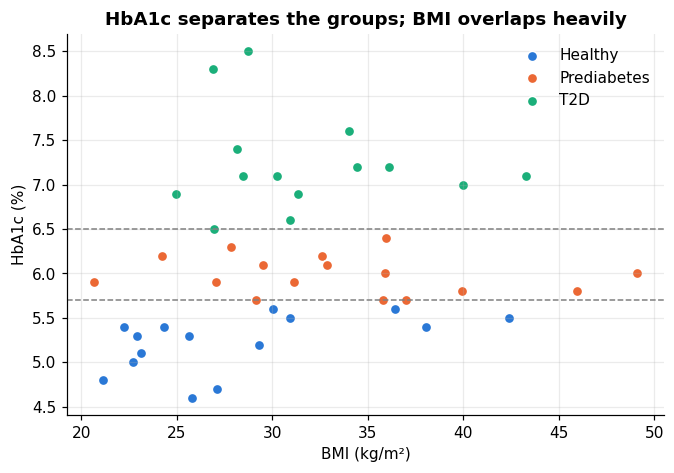

In [118]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for g in GROUP_ORDER:
    s = bio[bio.group == g]
    ax.scatter(s["BMI"], s["A1c"], s=45, color=GROUP_COLORS[g], edgecolor="white", linewidth=1, label=g)
for y in (5.7, 6.5):
    ax.axhline(y, color="gray", linestyle="--", linewidth=1)
ax.set(xlabel="BMI (kg/m²)", ylabel="HbA1c (%)", title="HbA1c separates the groups; BMI overlaps heavily")
ax.legend(frameon=False)
plt.show()

In [119]:
pd.crosstab(bio["group"], bio["Gender"]).reindex(GROUP_ORDER)

Gender,F,M
group,,
Healthy,10,5
Prediabetes,11,5
T2D,8,6


## 3. Coverage and the real sampling rates

The files have a row every minute, but the sensors don't measure that often: Dexcom every 5 minutes, Libre every 15. The in-between values are **interpolated** (you can see 84.0 → 84.13 → 84.27 in the first rows). Training a model on those invented minutes makes the data look smoother than it is, so for modeling we resample to each sensor's real rate.

In [121]:
rows = []
for sid, d in raw.items():
    t = d["timestamp"]
    gaps = t.diff().dt.total_seconds() / 60
    rows.append(dict(sid=sid, days=(t.max() - t.min()).total_seconds() / 86400,
                     longest_gap_min=gaps.max(),
                     libre_cov=d["libre"].notna().mean(), dexcom_cov=d["dexcom"].notna().mean(),
                     hr_cov=d["hr"].notna().mean(),
                     libre_floor_pct=(d["libre"] <= 40).mean() * 100,
                     n_meals=d["meal_type"].notna().sum()))
coverage = pd.DataFrame(rows).merge(bio[["sid", "group", "A1c"]], on="sid")
coverage.round(2).sort_values("sid")

,sid,days,longest_gap_min,libre_cov,dexcom_cov,hr_cov,libre_floor_pct,n_meals,group,A1c
0,1,10.23,1.0,1.00,0.97,0.99,0.00,43,Healthy,5.4
1,2,11.82,1.0,1.00,0.80,0.84,0.92,37,Healthy,5.5
2,3,10.12,2.0,1.00,0.98,0.99,0.00,35,T2D,6.5
3,4,9.91,1.0,0.98,1.00,1.00,0.00,62,Healthy,5.5
4,5,10.04,1.0,1.00,0.99,0.99,0.32,46,T2D,6.6
5,6,10.04,1.0,1.00,0.99,0.99,0.11,38,Healthy,5.2
6,7,7.23,23.0,1.00,1.00,1.00,35.51,17,Prediabetes,5.9
7,8,10.25,1.0,1.00,0.96,0.98,0.00,30,Prediabetes,5.8
8,9,9.98,1.0,1.00,0.99,0.99,0.00,41,Prediabetes,5.7
9,10,11.22,1.0,1.00,0.88,0.94,1.60,45,Prediabetes,5.7


In [122]:
# Evidence of interpolation: share of minutes where the value differs from the previous minute
d = raw[1]
for col, rate in [("dexcom", 5), ("libre", 15)]:
    s = d[col].dropna()
    second_diff = s.diff().diff().abs()
    print(f"{col:6s}: value changes every minute in {(s.diff() != 0).mean():.0%} of rows; "
          f"slope changes (real readings) in {(second_diff > 1e-6).mean():.0%} of rows (≈1/{rate} expected)")

dexcom: value changes every minute in 87% of rows; slope changes (real readings) in 17% of rows (≈1/5 expected)
libre : value changes every minute in 89% of rows; slope changes (real readings) in 6% of rows (≈1/15 expected)


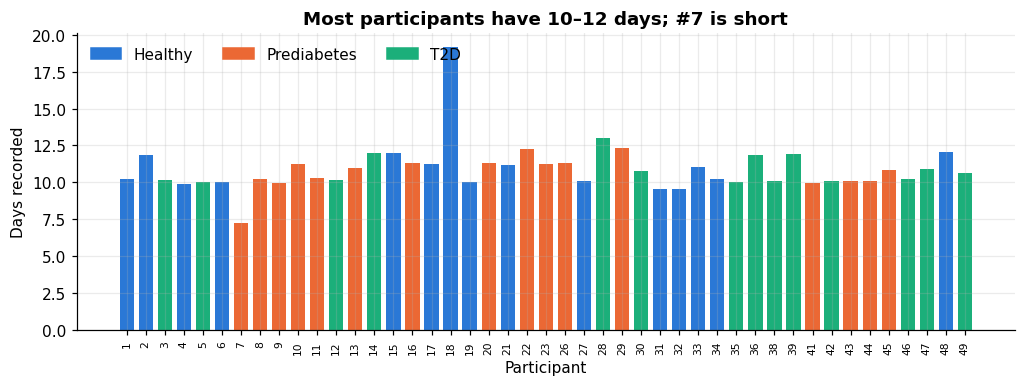

In [123]:
fig, ax = plt.subplots(figsize=(11, 3.5))
c = coverage.sort_values("sid")
ax.bar(c["sid"].astype(str), c["days"], color=[GROUP_COLORS[g] for g in c["group"]], width=0.75)
ax.set(xlabel="Participant", ylabel="Days recorded", title="Most participants have 10–12 days; #7 is short")
ax.tick_params(axis="x", labelsize=7, rotation=90)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g]) for g in GROUP_ORDER]
ax.legend(handles, GROUP_ORDER, frameon=False, ncols=3, loc="upper left")
plt.show()

In [124]:
# Flag participants to exclude or treat carefully
flags = coverage[(coverage.days < 8) | (coverage.libre_floor_pct > 10) | (coverage.longest_gap_min > 120)]
flags[["sid", "group", "days", "longest_gap_min", "libre_floor_pct"]].round(1)

,sid,group,days,longest_gap_min,libre_floor_pct
6,7,Prediabetes,7.2,23.0,35.5
14,15,Healthy,12.0,7.0,42.8
17,18,Healthy,19.2,901.0,0.1
29,32,Healthy,9.6,1.0,12.5


In [125]:
EXCLUDE = [7]   # 7 days only and Libre stuck at its 40 mg/dL floor a third of the time
print("Excluding:", EXCLUDE, "| Watch Libre for:", [s for s in flags.sid if s not in EXCLUDE])

def native_series(d, col, rate):
    """Resample an interpolated 1-minute column back to the sensor's real rate."""
    return d.set_index("timestamp")[col].resample(f"{rate}min").first()

dex5 = {sid: native_series(d, "dexcom", 5) for sid, d in raw.items() if sid not in EXCLUDE}
lib15 = {sid: native_series(d, "libre", 15) for sid, d in raw.items() if sid not in EXCLUDE}
print(f"Dexcom points at 5-min rate: {sum(s.notna().sum() for s in dex5.values()):,}")

Excluding: [7] | Watch Libre for: [15, 18, 32]
Dexcom points at 5-min rate: 124,976


## 4. Do the two glucose sensors agree?

Each person wore two sensors at once: Libre (arm) and Dexcom (abdomen). Their agreement tells us the **noise floor**: no model can honestly claim to be more accurate than the reference sensors are with each other.

Earlier exploration found the Libre reads roughly 30 mg/dL **lower** than the Dexcom, almost always. The cells below check whether that is random noise or a consistent offset, and whether one sensor lags the other.

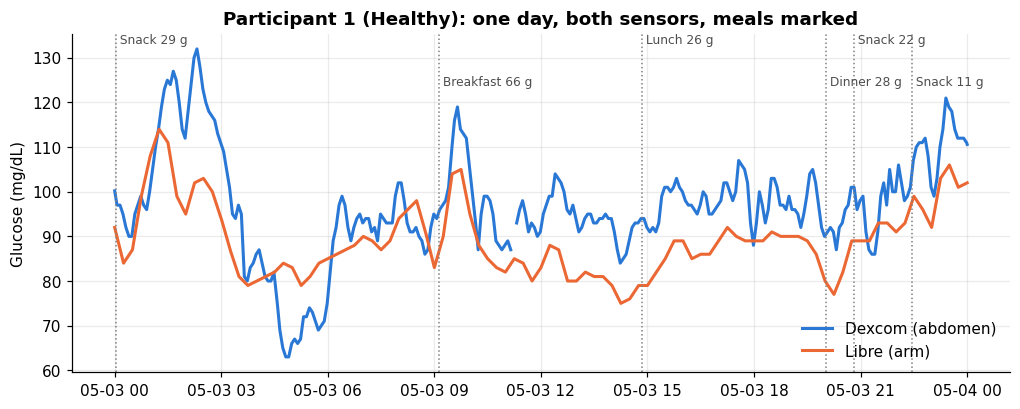

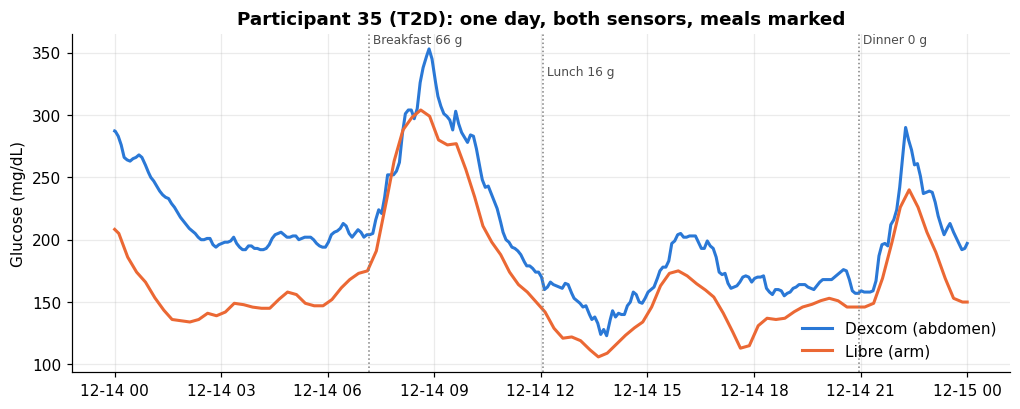

In [127]:
def one_day_plot(sid, day_index=2):
    d = raw[sid].set_index("timestamp")
    start = d.index.min().normalize() + pd.Timedelta(days=day_index)
    day = d[start:start + pd.Timedelta(days=1)]
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(day.index, day["dexcom"], color=SENSOR_COLORS["Dexcom"], label="Dexcom (abdomen)")
    ax.plot(day.index, day["libre"], color=SENSOR_COLORS["Libre"], label="Libre (arm)")
    top = ax.get_ylim()[1]
    for k, (t, row) in enumerate(day[day["meal_type"].notna()].iterrows()):
        ax.axvline(t, color="gray", linestyle=":", linewidth=1)
        # stagger labels on two rows so meals close in time don't overlap
        ax.text(t, top * (1.0 if k % 2 == 0 else 0.93), f" {row.meal_type} {row.carbs:.0f} g",
                fontsize=8, va="top", color="0.3")
    g = bio.set_index("sid").loc[sid, "group"]
    ax.set(ylabel="Glucose (mg/dL)", title=f"Participant {sid} ({g}): one day, both sensors, meals marked")
    ax.legend(frameon=False, loc="lower right")
    plt.show()

one_day_plot(1)
one_day_plot(35)   # a T2D participant with larger swings

In [128]:
agree = []
for sid, d in raw.items():
    if sid in EXCLUDE: continue
    both = d[["libre", "dexcom"]].dropna()
    slope, intercept = np.polyfit(both.libre, both.dexcom, 1)
    corrected = slope * both.libre + intercept
    lags = range(-30, 31)
    corr_by_lag = [d["libre"].shift(k).corr(d["dexcom"]) for k in lags]
    agree.append(dict(sid=sid,
        bias=(both.libre - both.dexcom).mean(),                               # Libre minus Dexcom
        mard_raw=(abs(both.libre - both.dexcom) / both.dexcom).mean() * 100,
        mard_after_linear_fix=(abs(corrected - both.dexcom) / both.dexcom).mean() * 100,
        corr=both.libre.corr(both.dexcom),
        best_lag_min=list(lags)[int(np.nanargmax(corr_by_lag))]))
agree = pd.DataFrame(agree).merge(bio[["sid", "group"]], on="sid")
print("Median across participants:")
agree[["bias", "mard_raw", "mard_after_linear_fix", "corr", "best_lag_min"]].median().round(1)

Median across participants:


bias                    -33.1
mard_raw                 23.5
mard_after_linear_fix     8.6
corr                      0.8
best_lag_min              7.0
dtype: float64

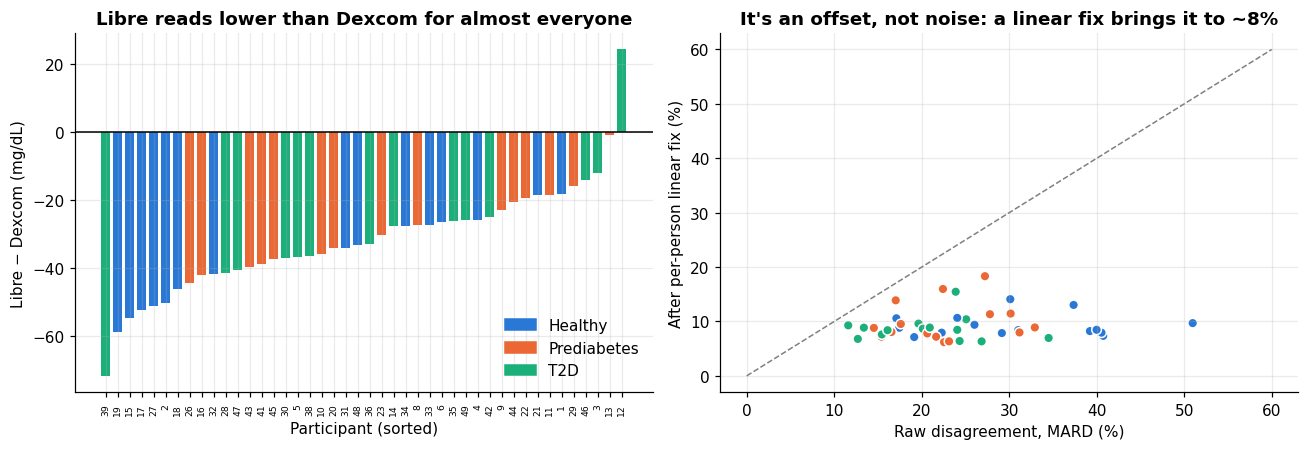

In [129]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

a = agree.sort_values("bias")
axes[0].bar(a["sid"].astype(str), a["bias"], color=[GROUP_COLORS[g] for g in a["group"]], width=0.75)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set(xlabel="Participant (sorted)", ylabel="Libre − Dexcom (mg/dL)",
            title="Libre reads lower than Dexcom for almost everyone")
axes[0].tick_params(axis="x", labelsize=6, rotation=90)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g]) for g in GROUP_ORDER]
axes[0].legend(handles, GROUP_ORDER, frameon=False, loc="lower right")

x = np.arange(len(agree))
axes[1].scatter(agree["mard_raw"], agree["mard_after_linear_fix"], s=40,
                c=[GROUP_COLORS[g] for g in agree["group"]], edgecolor="white")
axes[1].plot([0, 60], [0, 60], color="gray", linestyle="--", linewidth=1)
axes[1].set(xlabel="Raw disagreement, MARD (%)", ylabel="After per-person linear fix (%)",
            title="It's an offset, not noise: a linear fix brings it to ~8%")
plt.tight_layout(); plt.show()

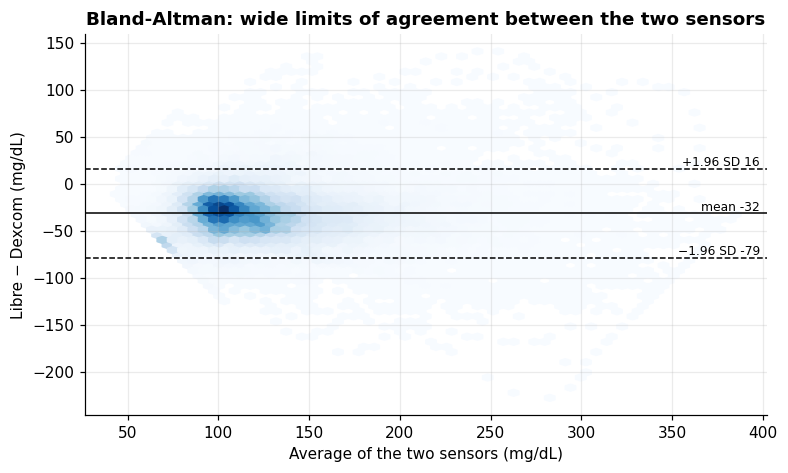

In [130]:
# Bland-Altman plot on the 5-minute grid, all participants pooled
pairs = []
for sid, d in raw.items():
    if sid in EXCLUDE: continue
    s = d.set_index("timestamp")[["libre", "dexcom"]].resample("5min").first().dropna()
    pairs.append(s)
pairs = pd.concat(pairs)
mean_, diff_ = (pairs.libre + pairs.dexcom) / 2, pairs.libre - pairs.dexcom
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hexbin(mean_, diff_, gridsize=60, cmap="Blues", mincnt=1)
m, sd = diff_.mean(), diff_.std()
for y, lab in [(m, f"mean {m:.0f}"), (m + 1.96 * sd, f"+1.96 SD {m + 1.96*sd:.0f}"), (m - 1.96 * sd, f"−1.96 SD {m - 1.96*sd:.0f}")]:
    ax.axhline(y, color="black", linestyle="--" if "SD" in lab else "-", linewidth=1)
    ax.text(0.99, y, lab, transform=ax.get_yaxis_transform(), ha="right", va="bottom", fontsize=8)
ax.set(xlabel="Average of the two sensors (mg/dL)", ylabel="Libre − Dexcom (mg/dL)",
       title="Bland-Altman: wide limits of agreement between the two sensors")
plt.show()

**Takeaway.** The sensors move together but disagree on level, and the Libre runs a few minutes *ahead* of the Dexcom. For modeling, use **Dexcom as the target** and keep the Libre for cross-checks.

## 5. Glucose patterns by group

In [132]:
dex_all = pd.concat([s.rename("glucose").to_frame().assign(sid=sid) for sid, s in dex5.items()]).dropna()
dex_all = dex_all.merge(bio[["sid", "group"]], on="sid")
dex_all.index = pd.concat([s.dropna() for s in dex5.values()]).index

def time_in_range(g):
    return pd.Series({"mean": g.mean(), "SD": g.std(), "CV %": g.std() / g.mean() * 100,
                      "% < 70": (g < 70).mean() * 100, "% 70–140": g.between(70, 140).mean() * 100,
                      "% 70–180": g.between(70, 180).mean() * 100, "% > 180": (g > 180).mean() * 100})

dex_all.groupby("group")["glucose"].apply(time_in_range).unstack().reindex(GROUP_ORDER).round(1)

,mean,SD,CV %,% < 70,% 70–140,% 70–180,% > 180
group,,,,,,,
Healthy,122.4,26.1,21.3,0.5,79.5,96.5,3.0
Prediabetes,136.5,33.1,24.3,0.5,64.5,90.0,9.6
T2D,166.0,51.4,31.0,0.2,33.1,68.0,31.8


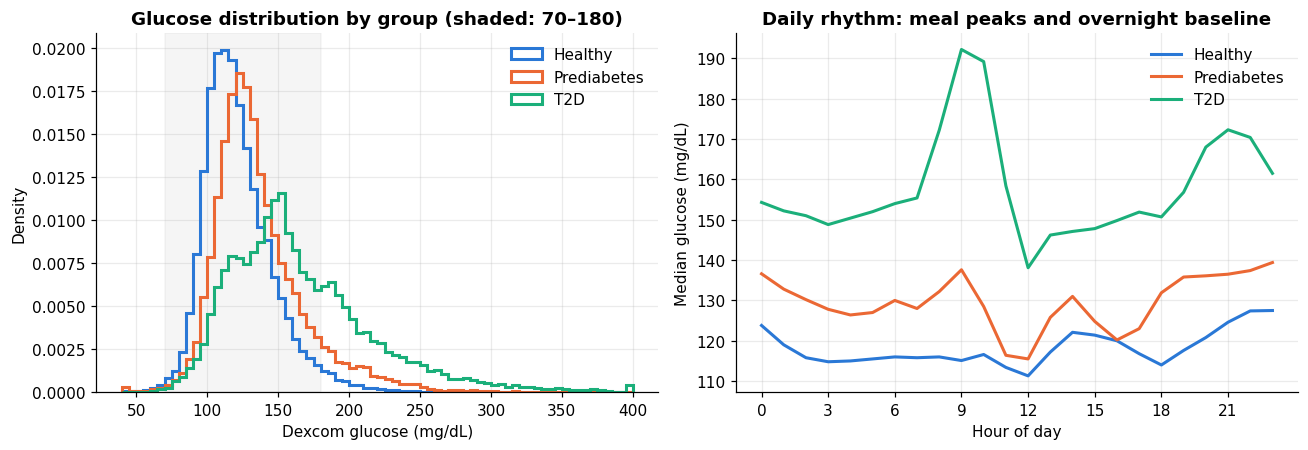

In [133]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
bins = np.arange(40, 405, 5)
for g in GROUP_ORDER:
    v = dex_all.loc[dex_all.group == g, "glucose"]
    axes[0].hist(v, bins=bins, density=True, histtype="step", linewidth=2, color=GROUP_COLORS[g], label=g)
axes[0].axvspan(70, 180, color="gray", alpha=0.08)
axes[0].set(xlabel="Dexcom glucose (mg/dL)", ylabel="Density", title="Glucose distribution by group (shaded: 70–180)")
axes[0].legend(frameon=False)

hourly = dex_all.assign(hour=dex_all.index.hour).groupby(["group", "hour"])["glucose"].median().unstack(0)
for g in GROUP_ORDER:
    axes[1].plot(hourly.index, hourly[g], color=GROUP_COLORS[g], label=g)
axes[1].set(xlabel="Hour of day", ylabel="Median glucose (mg/dL)", xticks=range(0, 24, 3),
            title="Daily rhythm: meal peaks and overnight baseline")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 6. Meal data quality

Meals are logged on the row where they start. Some values are clearly typos (carbs over 250 g, fiber in the thousands of grams), so we drop those. `Amount Consumed` above 100% (200, 300, 400…) is ambiguous rather than impossible, so those meals are kept and marked.

In [135]:
meals = pd.concat([d[d["meal_type"].notna()] for sid, d in raw.items() if sid not in EXCLUDE]).reset_index(drop=True)
meals = meals.merge(bio[["sid", "group"]], on="sid")
meal_cols = ["meal_kcal", "carbs", "protein", "fat", "fiber", "pct_consumed"]
print(meals["meal_type"].value_counts().to_string(), "\n")
meals[meal_cols].describe().round(1)

meal_type
Dinner       487
Breakfast    431
Lunch        429
Snack        342 



,meal_kcal,carbs,protein,fat,fiber,pct_consumed
count,1689.0,1689.0,1689.0,1689.0,1688.0,1625.0
mean,505.0,52.1,29.1,19.7,18.0,97.4
std,329.8,40.2,25.6,20.8,144.4,91.6
min,0.0,0.0,0.0,0.0,0.0,0.0
25%,268.0,24.0,10.0,10.0,0.0,100.0
50%,448.0,50.0,22.0,14.0,4.0,100.0
75%,712.0,73.0,44.0,30.0,7.0,100.0
max,2826.0,761.0,148.0,508.0,2830.0,900.0


In [136]:
meals["flag"] = ""
meals.loc[meals.carbs > 250, "flag"] += "carbs>250g "
meals.loc[meals.fiber > 60, "flag"] += "fiber>60g "
meals.loc[meals.fat > 150, "flag"] += "fat>150g "
meals.loc[(meals.meal_kcal == 0) & (meals.carbs == 0), "flag"] += "empty "
meals["flag"] = meals["flag"].str.strip()
print(f"{(meals.flag != '').sum()} of {len(meals)} meals flagged as impossible values (dropped below)")
print(f"Fiber typos are concentrated in a few people:", meals.loc[meals.flag.str.contains("fiber"), "sid"].value_counts().to_dict())

# 'Amount Consumed' above 100% (200, 300, 400...) looks like multiple servings, but it's unclear whether the
# logged macros already include them. Keep these meals, mark them, and use the macros as logged.
meals["multi_serving"] = meals.pct_consumed > 100
print(f"{meals.multi_serving.sum()} meals have Amount Consumed > 100% (values: {sorted(meals.loc[meals.multi_serving, 'pct_consumed'].unique())[:6]}...)")
meals[meals.flag != ""][["sid", "timestamp", "meal_type"] + meal_cols + ["flag"]].head(20)

75 of 1689 meals flagged as impossible values (dropped below)
Fiber typos are concentrated in a few people: {19: 15, 16: 10}
127 meals have Amount Consumed > 100% (values: [150.0, 200.0, 300.0, 375.0, 400.0, 500.0]...)


,sid,timestamp,meal_type,meal_kcal,carbs,protein,fat,fiber,pct_consumed,flag
339,10,2020-06-23 12:01:00,Snack,0.0,0.0,0.0,0.0,0.0,100.0,empty
434,12,2023-03-03 21:24:00,Dinner,0.0,0.0,0.0,0.0,0.0,0.0,empty
526,14,2023-05-18 21:47:00,Snack,0.0,0.0,0.0,0.0,0.0,100.0,empty
576,15,2024-02-03 17:34:00,Snack,0.0,0.0,0.0,0.0,0.0,100.0,empty
580,16,2023-07-14 11:58:00,Snack,280.0,38.0,4.0,12.0,480.0,1.0,fiber>60g
582,16,2023-07-15 12:13:00,Snack,460.0,45.0,12.0,23.0,230.0,3.0,fiber>60g
584,16,2023-07-16 12:06:00,Snack,220.0,19.0,7.0,13.0,510.0,1.0,fiber>60g
589,16,2023-07-18 16:00:00,Snack,580.0,73.0,7.0,31.0,230.0,2.0,fiber>60g
592,16,2023-07-19 20:00:00,Dinner,440.0,38.0,14.0,26.0,1020.0,1.0,fiber>60g
595,16,2023-07-20 16:00:00,Snack,410.0,63.0,6.0,15.0,480.0,1.0,fiber>60g


In [137]:
# Clean version used from here on: drop impossible values; missing % consumed -> 100%;
# for multi-serving entries use the macros as logged (pct capped at 100)
meals_clean = meals[meals.flag == ""].copy()
meals_clean["pct_consumed"] = meals_clean["pct_consumed"].fillna(100).clip(upper=100)
meals_clean["carbs_eaten"] = meals_clean["carbs"] * meals_clean["pct_consumed"] / 100

# Breakfast and lunch were partly standardized: the same carb values repeat many times
for mt in ["Breakfast", "Lunch"]:
    top = meals_clean.loc[meals_clean.meal_type == mt, "carbs"].value_counts().head(4)
    print(f"{mt:9s} most common carb values (g: count):", top.to_dict())

Breakfast most common carb values (g: count): {66.0: 263, 24.0: 88, 73.0: 80}
Lunch     most common carb values (g: count): {94.0: 86, 40.0: 44, 43.0: 44, 93.0: 43}


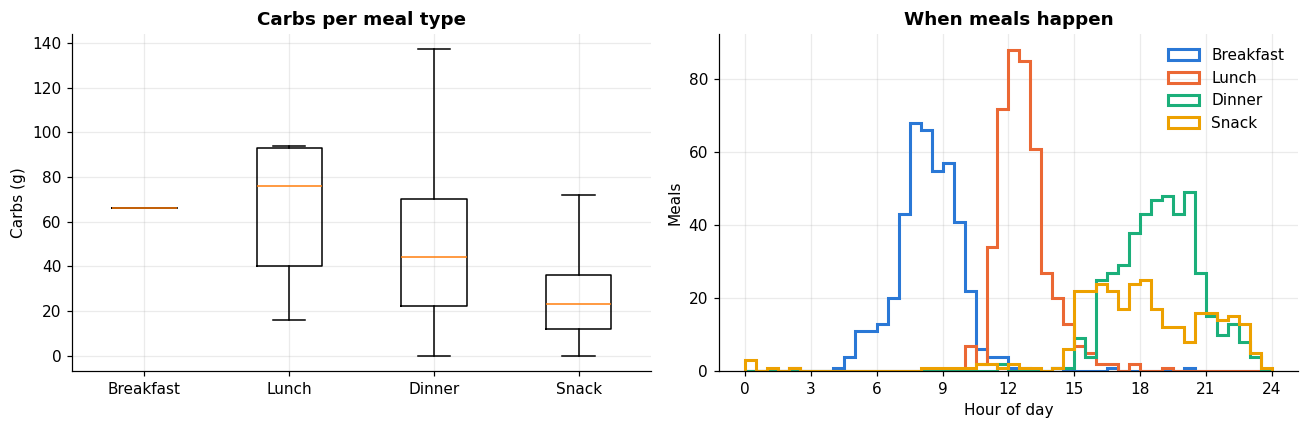

In [138]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = ["Breakfast", "Lunch", "Dinner", "Snack"]
data = [meals_clean.loc[meals_clean.meal_type == m, "carbs"] for m in order]
axes[0].boxplot(data, showfliers=False)
axes[0].set_xticks(range(1, len(order) + 1), order)
axes[0].set(ylabel="Carbs (g)", title="Carbs per meal type")
hour = meals_clean.timestamp.dt.hour + meals_clean.timestamp.dt.minute / 60
for i, m in enumerate(order):
    axes[1].hist(hour[meals_clean.meal_type == m], bins=np.arange(0, 24.5, 0.5), histtype="step",
                 linewidth=2, label=m, color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"][i])
axes[1].set(xlabel="Hour of day", ylabel="Meals", xticks=range(0, 25, 3), title="When meals happen")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 7. Post-meal glucose responses (the core signal for PINNs)

A physics-informed meal model says: carbs go in, glucose rises as they are absorbed, then falls back as the body clears it. To see that cleanly we use **isolated meals**: no other meal or snack within 3 hours before or after, so each response is not contaminated by the next one.

For each isolated meal we measure, from the Dexcom at its real 5-minute rate:
- **baseline**: average glucose in the 15 minutes before eating
- **rise**: peak above baseline within 3 hours
- **time to peak**
- **iAUC**: incremental area under the curve above baseline (the standard meal-response measure)
- **residual at 3 h**: how far above baseline glucose still is

In [140]:
WINDOW = pd.Timedelta("3h")
GRID = np.arange(0, 181, 5)          # minutes after meal start

all_meal_times = pd.concat([d.loc[d.meal_type.notna(), ["sid", "timestamp"]] for d in raw.values()])
responses, curves = [], []
for _, m in meals_clean.iterrows():
    sid, t0 = m.sid, m.timestamp
    others = all_meal_times.loc[(all_meal_times.sid == sid) & (all_meal_times.timestamp != t0), "timestamp"]
    if ((others - t0).abs() < WINDOW).any():
        continue                                           # not isolated
    g = dex5[sid]
    base = g[t0 - pd.Timedelta("15min"):t0].mean()
    post = g[t0:t0 + WINDOW]
    if np.isnan(base) or post.notna().sum() < 0.8 * len(GRID):
        continue                                           # too much missing data (or recording ended)
    rel = (post.index - t0).total_seconds() / 60
    curve = np.interp(GRID, rel[post.notna()], post.dropna().values) - base
    responses.append(dict(sid=sid, group=m.group, meal_type=m.meal_type, timestamp=t0,
                          carbs=m.carbs_eaten, protein=m.protein, fat=m.fat, fiber=m.fiber, kcal=m.meal_kcal,
                          baseline=base, rise=curve.max(), t_peak=GRID[curve.argmax()],
                          iauc=trapezoid(np.clip(curve, 0, None), GRID), residual_3h=curve[-1]))
    curves.append(curve)

resp = pd.DataFrame(responses)
curves = np.array(curves)
print(f"{len(resp)} isolated meal responses from {resp.sid.nunique()} participants")
resp.groupby("group")[["baseline", "rise", "t_peak", "iauc", "residual_3h"]].median().reindex(GROUP_ORDER).round(1)

1055 isolated meal responses from 44 participants


,baseline,rise,t_peak,iauc,residual_3h
group,,,,,
Healthy,108.7,38.5,60.0,2567.3,5.8
Prediabetes,118.8,54.6,70.0,3974.4,10.5
T2D,141.1,67.9,90.0,5464.1,16.5


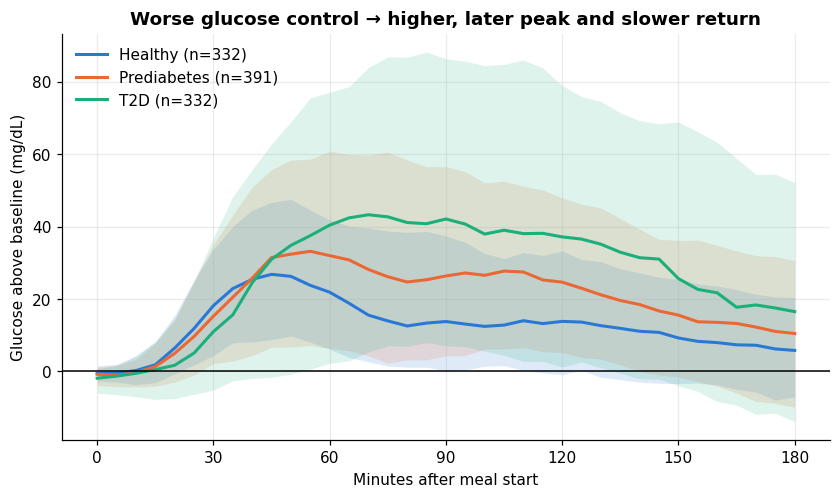

In [141]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for g in GROUP_ORDER:
    c = curves[resp.group.values == g]
    med, lo, hi = np.median(c, 0), np.percentile(c, 25, 0), np.percentile(c, 75, 0)
    ax.fill_between(GRID, lo, hi, color=GROUP_COLORS[g], alpha=0.15, linewidth=0)
    ax.plot(GRID, med, color=GROUP_COLORS[g], label=f"{g} (n={len(c)})")
ax.axhline(0, color="black", linewidth=1)
ax.set(xlabel="Minutes after meal start", ylabel="Glucose above baseline (mg/dL)", xticks=range(0, 181, 30),
       title="Worse glucose control → higher, later peak and slower return")
ax.legend(frameon=False)
plt.show()

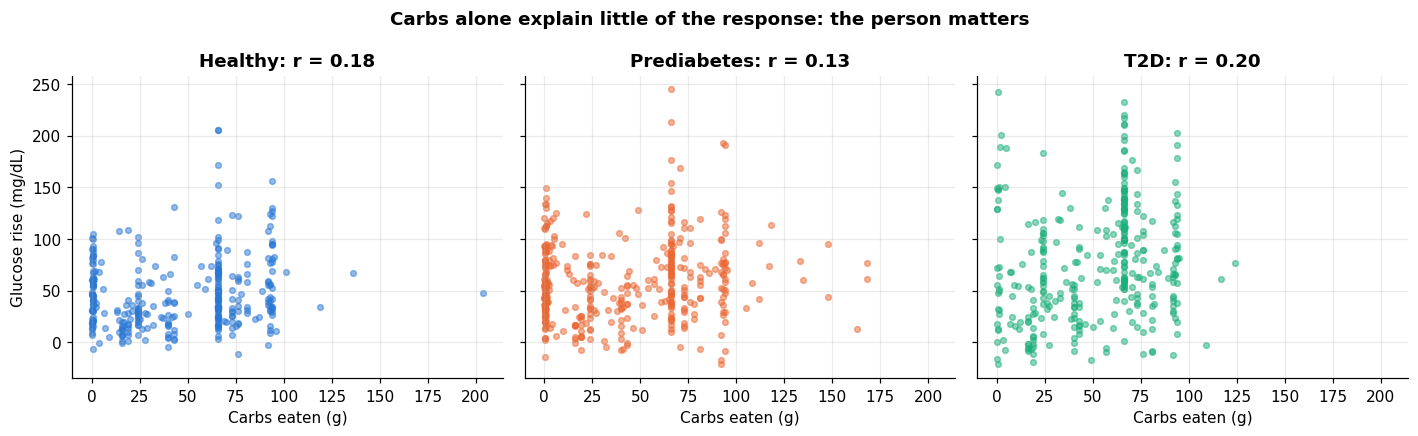

In [142]:
# Does the amount of carbs predict the rise? One panel per group, shared axes.
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True, sharey=True)
for ax, g in zip(axes, GROUP_ORDER):
    s = resp[resp.group == g]
    ax.scatter(s.carbs, s.rise, s=14, alpha=0.5, color=GROUP_COLORS[g])
    ax.set(title=f"{g}: r = {s.carbs.corr(s.rise):.2f}", xlabel="Carbs eaten (g)")
axes[0].set_ylabel("Glucose rise (mg/dL)")
fig.suptitle("Carbs alone explain little of the response: the person matters", fontweight="bold")
plt.tight_layout(); plt.show()

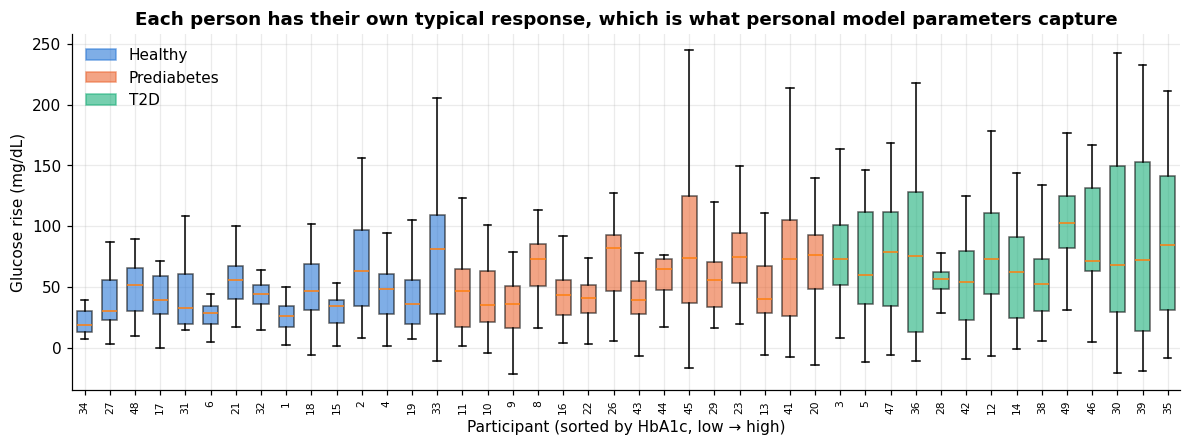

In [143]:
# Person-to-person variability: rise per participant, sorted by HbA1c
order_sids = bio[bio.sid.isin(resp.sid)].sort_values("A1c").sid.tolist()
fig, ax = plt.subplots(figsize=(13, 4.2))
box = ax.boxplot([resp.loc[resp.sid == s, "rise"] for s in order_sids], showfliers=False, patch_artist=True, widths=0.6)
ax.set_xticks(range(1, len(order_sids) + 1), [str(s) for s in order_sids])
for patch, s in zip(box["boxes"], order_sids):
    patch.set_facecolor(GROUP_COLORS[bio.set_index("sid").loc[s, "group"]]); patch.set_alpha(0.6)
ax.set(xlabel="Participant (sorted by HbA1c, low → high)", ylabel="Glucose rise (mg/dL)",
       title="Each person has their own typical response, which is what personal model parameters capture")
ax.tick_params(axis="x", labelsize=7, rotation=90)
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g], alpha=0.6) for g in GROUP_ORDER]
ax.legend(handles, GROUP_ORDER, frameon=False, loc="upper left")
plt.show()

In [144]:
# How much of the rise is explained by the person vs. the meal?  (share of variance between people)
between = resp.groupby("sid")["rise"].mean().var()
total = resp["rise"].var()
print(f"Share of rise variance explained by *who* ate the meal: {between / total:.0%}")
print("Correlation of each macro with the rise (all groups):")
print(resp[["carbs", "protein", "fat", "fiber", "kcal", "baseline"]].corrwith(resp["rise"]).round(2).to_string())

Share of rise variance explained by *who* ate the meal: 20%
Correlation of each macro with the rise (all groups):
carbs       0.17
protein    -0.11
fat         0.03
fiber      -0.18
kcal        0.08
baseline    0.01


In [145]:
# Standardized breakfasts: same food, different people -> the cleanest comparison in the dataset
std_carb = meals_clean.loc[meals_clean.meal_type == "Breakfast", "carbs"].mode()[0]
std = resp[(resp.meal_type == "Breakfast") & (resp.carbs.round() == std_carb)]
print(f"Standard breakfast ({std_carb:.0f} g carbs): {len(std)} isolated responses from {std.sid.nunique()} people")
std.groupby("group")[["rise", "t_peak", "iauc"]].agg(["median", "count"]).reindex(GROUP_ORDER).round(1)

Standard breakfast (66 g carbs): 208 isolated responses from 36 people


rise       t_peak          iauc      
            median count median count  median count
group                                              
Healthy       47.3    69   50.0    69  3353.5    69
Prediabetes   72.5    63   65.0    63  5561.7    63
T2D          117.4    76   75.0    76  9312.0    76

## 8. Activity and glucose

In [147]:
act = []
for _, r in resp.iterrows():
    d = raw[r.sid].set_index("timestamp")
    w = d.loc[r.timestamp:r.timestamp + pd.Timedelta("2h")]
    act.append(dict(mean_intensity_2h=w["intensity"].mean(), hr_2h=w["hr"].mean(),
                    active_min=(w["intensity"] >= 2).sum()))  # minutes of moderate-or-vigorous activity
resp = pd.concat([resp, pd.DataFrame(act)], axis=1)

resp["walked"] = np.where(resp.active_min >= 10, "≥10 active min", "<10 active min")
resp.groupby(["group", "walked"])["rise"].agg(["median", "count"]).round(1)

median  count
group       walked                       
Healthy     <10 active min    39.9    143
            ≥10 active min    36.0    189
Prediabetes <10 active min    60.1    133
            ≥10 active min    50.6    258
T2D         <10 active min    74.1    101
            ≥10 active min    66.0    231

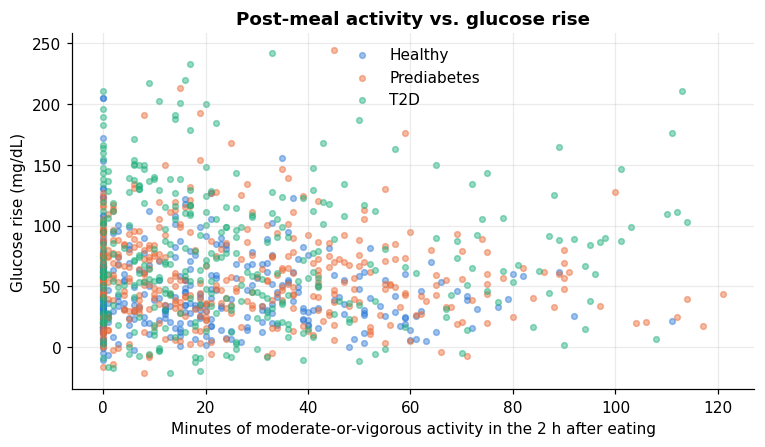

Correlation active minutes vs rise by group: {'Healthy': -0.13, 'Prediabetes': -0.09, 'T2D': -0.02}


In [148]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for g in GROUP_ORDER:
    s = resp[resp.group == g]
    ax.scatter(s.active_min, s.rise, s=14, alpha=0.45, color=GROUP_COLORS[g], label=g)
ax.set(xlabel="Minutes of moderate-or-vigorous activity in the 2 h after eating", ylabel="Glucose rise (mg/dL)",
       title="Post-meal activity vs. glucose rise")
ax.legend(frameon=False)
plt.show()
print("Correlation active minutes vs rise by group:",
      {g: round(s.active_min.corr(s.rise), 2) for g, s in resp.groupby("group")})

## 9. Save cleaned data for modeling

Writes to a new `processed/` folder next to this notebook:
- `dexcom_5min.csv`: Dexcom glucose at its real 5-minute rate, all included participants
- `meals_clean.csv`: meals with typos removed and normalized labels
- `meal_responses.csv`: one row per isolated meal with rise, peak time, iAUC and activity
- `participants.csv`: demographics, group, sensor agreement and coverage per person

In [150]:
out = DATA_DIR / "processed"
out.mkdir(exist_ok=True)

dex_long = pd.concat([s.rename("glucose").rename_axis("timestamp").reset_index().assign(sid=sid)
                      for sid, s in dex5.items()])
dex_long.to_csv(out / "dexcom_5min.csv", index=False)
meals_clean.drop(columns=["libre", "dexcom", "hr", "activity_kcal", "mets", "intensity"], errors="ignore").to_csv(out / "meals_clean.csv", index=False)
resp.to_csv(out / "meal_responses.csv", index=False)
participants = bio.merge(coverage.drop(columns=["group", "A1c"]), on="sid").merge(agree.drop(columns="group"), on="sid", how="left")
participants.to_csv(out / "participants.csv", index=False)
for f in sorted(out.glob("*.csv")):
    print(f"{f.name:22s} {f.stat().st_size / 1e6:6.1f} MB")

dexcom_5min.csv           4.1 MB
meal_responses.csv        0.2 MB
meals_clean.csv           0.2 MB
participant_flags.csv     0.0 MB
participants.csv          0.0 MB
unlogged_rises.csv        0.0 MB


## What this means for the PINN models

- **Target:** Dexcom at 5-minute resolution. Treat the Libre as a second, biased, slightly earlier view of the same glucose.
- **Inputs:** meal start times and carbs eaten (from `meals_clean.csv`), activity from the harmonized 0–3 intensity scale.
- **Training units:** isolated meal responses for fitting meal-absorption ODEs; full days for forecasting.
- **Missing piece:** no insulin time series and no medication data, so the model must treat insulin action as an unknown it infers.
- **Splits:** always by participant (leave-one-subject-out). Never mix one person's days across train and test.
- **Next notebook:** fit a simple glucose ODE to each person's isolated meals (an inverse problem) and check whether the fitted parameters separate the three groups.

## 10. Factors not recorded that could make the model learn wrong patterns

A model only knows what it's shown. When something affects glucose but isn't in the data, the model blames whatever *is* in the data: a meal, a person's parameters, or their diagnostic group. This section lists those hidden factors, checks the ones we can detect indirectly, and records how the modeling notebooks should handle each.

| # | Factor | Recorded? | Checked below? | Main risk for the model |
|---|---|---|---|---|
| 10.1 | Diagnostic group uncertainty (A1c vs fasting glucose, ethnicity) | Partly | Yes | Group comparisons built on fuzzy labels |
| 10.2 | Menstrual cycle phase | No | Indirectly (age, drift) | Insulin sensitivity drifts within a person |
| 10.3 | Unlogged food and drinks | No | Yes | Glucose rises with no cause; distorted parameters |
| 10.4 | Fitbit not worn | Implicitly | Yes | "Missing" mistaken for "inactive" |
| 10.5 | Dawn phenomenon | No | Yes | Morning baseline is not flat |
| 10.6 | Sensor compression lows overnight | No | Yes | False dips learned as real physiology |
| 10.7 | Time of day | Derivable | Yes | Same meal, different response by hour |
| 10.8 | Diabetes medications | No | No | T2D parameters reflect *treated* physiology |
| 10.9 | Carb estimation error | No | No | The model's *input* is noisy |
| 10.10 | Meal composition (fat, protein, fiber, carb type) | Partly | Partly | Same carbs, different curve shape |
| 10.11 | Sleep, stress, illness | No | No | Day-to-day drift in insulin sensitivity |
| 10.12 | Prior-day exercise | Partly | No | Insulin sensitivity raised for a day or two |
| 10.13 | Alcohol and caffeine | No | No | Unexplained lows or raised glucose |
| 10.14 | Behavior change from self-monitoring | No | No | Data cleaner than real life |

Citations are numbered [1]–[19] and listed at the end of the section.

### 10.1 Diagnostic group uncertainty

Groups in this notebook come from a single HbA1c test. `bio.csv` also has a fasting glucose test, which uses different cut-offs (below 100 mg/dL healthy, 100–125 prediabetes, 126 and above diabetes). If the two tests disagree for many people, the groups are less clear-cut than they look.

HbA1c also depends on more than glucose: red blood cell lifespan, anemia, and ethnicity all shift it. In the Diabetes Prevention Program, A1c differed by race and ethnicity among people with the *same* glucose tolerance [1]. Most participants here identify as Hispanic/Latino or Black, so this is relevant.

In [154]:
fg = bio["fasting_glucose"]
bio["fg_group"] = np.select([fg >= 126, fg >= 100], ["T2D", "Prediabetes"], default="Healthy")
bio["groups_agree"] = bio["group"] == bio["fg_group"]

print("Rows: group by HbA1c | Columns: group by fasting glucose")
display(pd.crosstab(bio["group"], bio["fg_group"]).reindex(index=GROUP_ORDER, columns=GROUP_ORDER))
print(f"{(~bio.groups_agree).sum()} of {len(bio)} participants change group depending on the test")
print("\nSelf-identified ethnicity:", bio["ethnicity"].str.strip().value_counts().to_dict())
bio.loc[~bio.groups_agree, ["sid", "A1c", "fasting_glucose", "group", "fg_group"]]

Rows: group by HbA1c | Columns: group by fasting glucose


fg_group,Healthy,Prediabetes,T2D
group,,,
Healthy,10,5,0
Prediabetes,1,11,4
T2D,0,2,12


12 of 45 participants change group depending on the test

Self-identified ethnicity: {'Hispanic/Latino': 34, 'White': 7, 'African American': 3, 'Black, African American': 1}


,sid,A1c,fasting_glucose,group,fg_group
2,3,6.5,118,T2D,Prediabetes
3,4,5.5,105,Healthy,Prediabetes
17,18,5.4,103,Healthy,Prediabetes
22,23,6.2,135,Prediabetes,T2D
26,29,6.1,136,Prediabetes,T2D
28,31,5.1,102,Healthy,Prediabetes
29,32,5.3,100,Healthy,Prediabetes
30,33,5.6,116,Healthy,Prediabetes
33,36,6.9,101,T2D,Prediabetes
36,41,6.3,138,Prediabetes,T2D


**Handling in the models:** when testing whether fitted parameters track diabetes status, use **A1c as a continuous value** rather than three boxes, and repeat the analysis without the discordant participants. A finding that survives both is robust.

### 10.2 Menstrual cycle phase

Menopause status, cycle phase, hormonal contraception and hormone therapy were not recorded. Evidence on the size of the effect is mixed:

- Lin et al. [2]: in 49 healthy young women wearing a Dexcom G6, daily median glucose was about 0.16 mmol/L (≈3 mg/dL) higher in the luteal phase than the late-follicular phase.
- Valdes & Elkind-Hirsch [3]: minimal-model insulin sensitivity fell from 6.20 (early follicular) to 3.20 (mid-luteal) in 8 women; glucose effectiveness did not change.
- Yeung et al. (BioCycle) [4]: in 257 women, HOMA-IR rose from about 1.35 to 1.59 in the early luteal phase, a change the authors described as minor.
- Diamond et al. [5]: no difference in insulin sensitivity between phases using the euglycemic clamp.
- Gamarra & Trimboli [6]: systematic review (type 1 diabetes) finding the evidence inconclusive and at high risk of bias.

Age is the only available proxy for whether someone is still cycling.

In [157]:
women = bio[bio["Gender"].str.strip() == "F"].copy()
women["cycle_status"] = pd.cut(women["Age"], [0, 44, 55, 120],
                               labels=["<45: likely cycling", "45-55: uncertain", ">55: likely post-menopausal"])
print(f"Women: {len(women)} of {len(bio)} participants")
display(pd.crosstab(women["cycle_status"], women["group"]).reindex(columns=GROUP_ORDER))
bio["cycle_status"] = bio["sid"].map(women.set_index("sid")["cycle_status"]).astype(object).fillna("male")

Women: 29 of 45 participants


group,Healthy,Prediabetes,T2D
cycle_status,,,
<45: likely cycling,5,1,0
45-55: uncertain,4,4,4
>55: likely post-menopausal,1,6,4


In [158]:
# Indirect check: does the standard-breakfast response drift across study days more for younger women?
std_b = resp[(resp.meal_type == "Breakfast") & (resp.carbs.round() == std_carb)].copy()
start = {sid: d["timestamp"].min().normalize() for sid, d in raw.items()}
std_b["study_day"] = [(t.normalize() - start[s]).days for s, t in zip(std_b.sid, std_b.timestamp)]
std_b = std_b.merge(bio[["sid", "cycle_status"]], on="sid")

def slope_per_day(s):
    return np.polyfit(s.study_day, s.rise, 1)[0] if s.study_day.nunique() >= 3 else np.nan

drift = pd.DataFrame([{"sid": sid, "cycle_status": cs, "rise_slope_per_day": slope_per_day(s)}
                      for (sid, cs), s in std_b.groupby(["sid", "cycle_status"])]).dropna()
drift["abs_slope"] = drift["rise_slope_per_day"].abs()
print("Change in standard-breakfast rise per study day (mg/dL/day), by cycle status:")
drift.groupby("cycle_status")["abs_slope"].agg(["median", "count"]).round(2)

Change in standard-breakfast rise per study day (mg/dL/day), by cycle status:


,median,count
cycle_status,,
45-55: uncertain,3.52,11
<45: likely cycling,4.33,5
>55: likely post-menopausal,4.15,6
male,4.73,14


**Reading this:** a larger typical drift for "<45: likely cycling" than for men or post-menopausal women would hint at a cycle effect. With so few people per group it can only hint, never prove.

**Handling in the models:** allow insulin sensitivity to drift slowly day to day within each person (the literature suggests anywhere from no change up to about a 50% swing [3, 5]), keep glucose effectiveness fixed per person [3], and run sensitivity analyses excluding women under 45 and women 55 and under.

### 10.3 Unlogged food and drinks

The model assumes glucose only rises after a logged meal. Below we count clear daytime rises (at least 30 mg/dL within an hour, 06:00–23:00) with no meal logged from 90 minutes before to 30 minutes after. These are likely unlogged snacks or drinks, though stress, exercise effects or sensor noise can also cause them.

In [161]:
meal_times = {sid: d.loc[d.meal_type.notna(), "timestamp"] for sid, d in raw.items()}

def unlogged_rises(sid, min_rise=30):
    g = dex5[sid]
    rise = g.shift(-12) - g                     # change over the next 60 min (12 x 5 min)
    cand = rise[(rise >= min_rise) & (g.index.hour >= 6) & (g.index.hour < 23)].index
    mt = meal_times[sid].values
    events, last = [], None
    for t in cand:
        if last is not None and t - last < pd.Timedelta("2h"):
            continue                            # same excursion
        near = (mt >= np.datetime64(t - pd.Timedelta("90min"))) & (mt <= np.datetime64(t + pd.Timedelta("30min")))
        if not near.any():
            events.append(t); last = t
    return events

unlogged = {sid: unlogged_rises(sid) for sid in dex5}
u = pd.DataFrame({"sid": list(unlogged),
                  "unlogged_per_day": [len(v) / max(coverage.set_index("sid").loc[s, "days"], 1) for s, v in unlogged.items()],
                  "logged_per_day": [len(meal_times[s]) / max(coverage.set_index("sid").loc[s, "days"], 1) for s in unlogged]})
u = u.merge(bio[["sid", "group"]], on="sid")
print(f"{(u.unlogged_per_day >= 1).sum()} of {len(u)} participants average at least one unlogged rise per day")
u.groupby("group")[["unlogged_per_day", "logged_per_day"]].median().reindex(GROUP_ORDER).round(2)

26 of 44 participants average at least one unlogged rise per day


,unlogged_per_day,logged_per_day
group,,
Healthy,0.88,3.78
Prediabetes,1.31,3.63
T2D,1.64,2.77


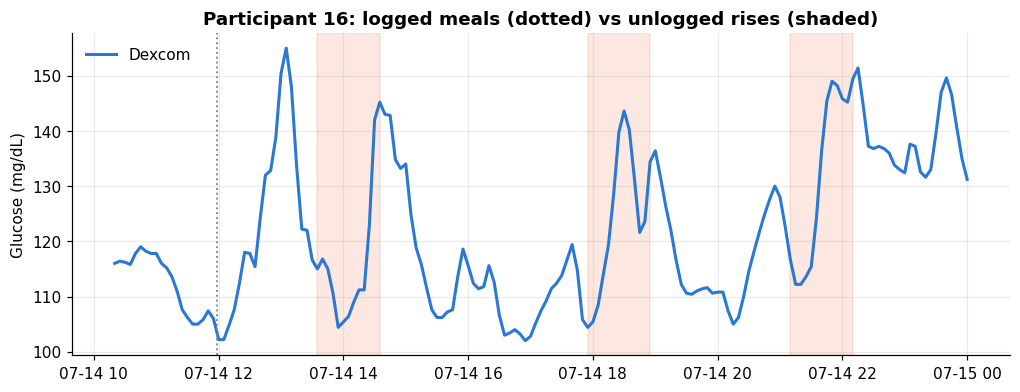

In [162]:
# Show one example day with unlogged rises marked
sid_ex = u.sort_values("unlogged_per_day", ascending=False).sid.iloc[len(u) // 4]
ev = pd.Series(unlogged[sid_ex])
day0 = ev.dt.normalize().value_counts().idxmax()
g = dex5[sid_ex][day0:day0 + pd.Timedelta(days=1)]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(g.index, g.values, color=SENSOR_COLORS["Dexcom"], label="Dexcom")
for t in meal_times[sid_ex][(meal_times[sid_ex] >= day0) & (meal_times[sid_ex] < day0 + pd.Timedelta(days=1))]:
    ax.axvline(t, color="gray", linestyle=":", linewidth=1.2)
for t in ev[(ev >= day0) & (ev < day0 + pd.Timedelta(days=1))]:
    ax.axvspan(t, t + pd.Timedelta("1h"), color="#eb6834", alpha=0.15)
ax.set(ylabel="Glucose (mg/dL)", title=f"Participant {sid_ex}: logged meals (dotted) vs unlogged rises (shaded)")
ax.legend(frameon=False, loc="upper left")
plt.show()

**Handling in the models:** fit the first PINN on isolated logged meals only (section 7). For whole-day models, add an "unexplained input" term the model can switch on, penalize its use, and report how often it fires per group. Section 10.14 explains why logging may also be incomplete.

### 10.4 Fitbit not worn

A missing heart-rate value usually means the watch was off (charging, showering), not that the person was resting. Treating gaps as zero activity teaches the model the wrong thing.

In [165]:
wear = pd.DataFrame({"sid": list(raw),
                     "hr_missing_pct": [d["hr"].isna().mean() * 100 for d in raw.values()]}).merge(bio[["sid", "group"]], on="sid")
print(f"Median minutes without heart rate: {wear.hr_missing_pct.median():.1f}%")
print("Participants missing more than 20%:", wear.loc[wear.hr_missing_pct > 20, "sid"].tolist())

Median minutes without heart rate: 7.0%
Participants missing more than 20%: [28, 32, 33, 34, 41]


**Handling in the models:** keep activity as missing (with a "worn" indicator) instead of filling with zero, and don't compute post-meal activity for meals where the watch wasn't worn.

### 10.5 Dawn phenomenon

In the early morning, hormones such as cortisol and growth hormone raise glucose before breakfast, particularly in type 2 diabetes [7]. A model that assumes a flat fasting baseline will be slightly wrong every morning.

In [168]:
def dawn_rise(g):
    by_day = g.groupby(g.index.date)
    return np.nanmedian([s[s.index.hour == 6].mean() - s[s.index.hour == 3].mean() for _, s in by_day])

dawn = pd.DataFrame({"sid": list(dex5), "dawn_rise": [dawn_rise(g) for g in dex5.values()]}).merge(bio[["sid", "group"]], on="sid")
print("Median glucose change from 03:00 to 06:00 (mg/dL), before breakfast:")
dawn.groupby("group")["dawn_rise"].median().reindex(GROUP_ORDER).round(1)

Median glucose change from 03:00 to 06:00 (mg/dL), before breakfast:


group
Healthy       -1.1
Prediabetes   -0.1
T2D            5.0
Name: dawn_rise, dtype: float64

**Handling in the models:** give the baseline a small time-of-day term, or exclude meals starting before about 07:00 from the first PINN.

### 10.6 Sensor compression lows overnight

Lying on a sensor squeezes the tissue around it and can produce a false low that recovers when the person moves [8]. The signature is a sharp drop followed by a quick recovery, overnight.

In [171]:
def dip_and_recover(g, drop=-25, recover=20):
    n = g[g.index.hour < 6]
    fall = n.shift(-4) - n                   # change over the next 20 min
    back = n.shift(-12) - n.shift(-4)        # recovery over the following 40 min
    return int(((fall <= drop) & (back >= recover)).sum())

nights = {sid: max((d.timestamp.max() - d.timestamp.min()).days, 1) for sid, d in raw.items()}
comp = pd.DataFrame({"sid": list(dex5),
                     "dexcom_events_per_night": [dip_and_recover(dex5[s]) / nights[s] for s in dex5],
                     "libre_events_per_night": [dip_and_recover(lib15[s].reindex(dex5[s].index).interpolate(limit=2)) / nights[s] for s in dex5]})
comp[["dexcom_events_per_night", "libre_events_per_night"]].describe().loc[["mean", "50%", "max"]].round(2)

,dexcom_events_per_night,libre_events_per_night
mean,0.2,0.0
50%,0.1,0.0
max,0.9,0.1


**Handling in the models:** flag overnight dip-and-recover windows and exclude them from training targets. The Libre's 15-minute sampling can hide short dips, so a low count for the Libre doesn't prove it is unaffected.

### 10.7 Time of day

The same meal usually produces a higher glucose response later in the day: a meta-analysis found responses to identical meals were lower during the day than at night [9]. In this study, breakfast and lunch were partly standardized while dinner was free choice, so meal type, food and time of day are tangled together.

In [174]:
resp["hour"] = resp.timestamp.dt.hour + resp.timestamp.dt.minute / 60
resp["carb_norm_rise"] = resp["rise"] / resp["carbs"].clip(lower=10)   # rise per gram of carbs, guarded against tiny meals
resp.groupby("meal_type")[["hour", "carbs", "rise", "carb_norm_rise", "t_peak"]].median().reindex(["Breakfast", "Lunch", "Dinner", "Snack"]).round(2)

,hour,carbs,rise,carb_norm_rise,t_peak
meal_type,,,,,
Breakfast,8.22,66.0,61.62,1.50,60.0
Lunch,12.55,43.0,40.53,0.85,90.0
Dinner,19.02,35.0,57.52,1.36,90.0
Snack,18.13,15.0,42.90,2.05,70.0


**Handling in the models:** include time of day (or meal slot) as an input to the absorption and clearance terms, and compare like with like: the standard breakfast is the cleanest within-slot comparison.

### 10.8–10.14 Factors that can't be checked in this data

**10.8 Diabetes medications.** Not recorded. Metformin mainly lowers glucose production by the liver [10], and GLP-1 based drugs slow stomach emptying, which flattens and delays the post-meal rise [11]. Fitted T2D parameters therefore describe *treated* physiology and will vary more between people.
*Handling:* state this explicitly; don't interpret T2D parameters as untreated disease; expect wider spread in absorption rates for T2D.

**10.9 Carb estimation error.** Carbs come from food logs and photos, so the model's *input* is uncertain, not just its output. Carb-counting errors are common and large enough to matter for glucose control [12].
*Handling:* let the model learn a per-meal "effective carbs" scaling factor with a prior centered at 1, instead of trusting logged grams exactly.

**10.10 Meal composition.** Fat, protein and glycemic index all change the size and timing of the post-meal curve, not just carbs [13]. Fat, protein and fiber are logged here; carb type is not.
*Handling:* let fat, protein and fiber modulate the absorption rate in the ODE.

**10.11 Sleep, stress and illness.** A single night of about 4 hours' sleep reduced insulin sensitivity in healthy people [14]. Sleep isn't in this data, and stress and illness weren't recorded either.
*Handling:* the same day-to-day drift in insulin sensitivity used for the menstrual cycle (10.2) absorbs these too.

**10.12 Prior-day exercise.** Physical activity improves insulin sensitivity for hours to a day or two afterwards [15].
*Handling:* include the previous day's active minutes as an input, using the harmonized intensity scale.

**10.13 Alcohol and caffeine.** Evening alcohol can lower glucose into the next morning [16], and caffeine has been shown to raise post-meal glucose in type 2 diabetes [17]. Unsweetened coffee was permitted between meals, and neither was logged.
*Handling:* treat as a limitation; unexplained overnight lows and modestly raised responses are possible.

**10.14 Behavior change from self-monitoring.** Recording what you eat tends to change what you eat [18]. Photographing every meal probably made eating more regular and careful than usual, and some snacks may have gone unrecorded (10.3).
*Handling:* treat model accuracy here as a best case; real-world data will be messier.

### 10.15 Save the flags for the modeling notebooks

In [178]:
flags = (bio[["sid", "group", "A1c", "fasting_glucose", "fg_group", "groups_agree", "Gender", "Age", "cycle_status"]]
         .merge(u[["sid", "unlogged_per_day"]], on="sid", how="left")
         .merge(wear[["sid", "hr_missing_pct"]], on="sid", how="left")
         .merge(dawn[["sid", "dawn_rise"]], on="sid", how="left")
         .merge(comp[["sid", "dexcom_events_per_night"]], on="sid", how="left"))
flags["excluded"] = flags["sid"].isin(EXCLUDE)
flags.to_csv(out / "participant_flags.csv", index=False)

pd.Series([t for v in unlogged.values() for t in v], name="unlogged_rise_start").to_frame() \
  .assign(sid=[s for s, v in unlogged.items() for _ in v]).to_csv(out / "unlogged_rises.csv", index=False)
print("Saved participant_flags.csv and unlogged_rises.csv to processed/")
flags.head()

Saved participant_flags.csv and unlogged_rises.csv to processed/


,sid,group,A1c,fasting_glucose,fg_group,groups_agree,Gender,Age,cycle_status,unlogged_per_day,hr_missing_pct,dawn_rise,dexcom_events_per_night,excluded
0,1,Healthy,5.4,91,Healthy,True,M,27,male,0.586598,0.760353,-2.200000,0.400000,False
1,2,Healthy,5.5,93,Healthy,True,F,49,45-55: uncertain,0.507519,16.088106,-3.783333,0.000000,False
2,3,T2D,6.5,118,Prediabetes,False,F,59,>55: likely post-menopausal,0.592633,0.597322,-1.750000,0.000000,False
3,4,Healthy,5.5,105,Prediabetes,False,F,33,<45: likely cycling,0.403531,0.280210,0.541667,0.222222,False
4,5,T2D,6.6,144,T2D,True,F,51,45-55: uncertain,1.195103,1.224066,0.850000,0.100000,False


### Summary: one model structure that absorbs most of these

Most hidden factors make a person's response change from day to day without the data saying why. Rather than one fix per factor, the modeling notebooks will use:

1. **Stable per-person core parameters** (absorption rate, glucose effectiveness).
2. **Slowly drifting insulin sensitivity** per person, covering the menstrual cycle, sleep, stress, illness and prior-day exercise.
3. **Per-meal effective-carb scaling**, covering carb estimation error and some composition effects.
4. **An "unexplained input" term**, covering unlogged food and drinks, used sparingly and reported.
5. **Sensitivity analyses**: continuous A1c instead of groups; excluding discordant labels; excluding likely-cycling women.

### References

[1] Herman WH, et al. Differences in A1C by race and ethnicity among patients with impaired glucose tolerance in the Diabetes Prevention Program. *Diabetes Care*. 2007;30(10):2453–2457.
[2] Lin G, Siddiqui R, Lin Z, et al. Blood glucose variance measured by continuous glucose monitors across the menstrual cycle. *npj Digital Medicine*. 2023;6:140. doi:10.1038/s41746-023-00884-x
[3] Valdes CT, Elkind-Hirsch KE. Intravenous glucose tolerance test-derived insulin sensitivity changes during the menstrual cycle. *J Clin Endocrinol Metab*. 1991;72(3):642–646.
[4] Yeung EH, Zhang C, Mumford SL, et al. Longitudinal study of insulin resistance and sex hormones over the menstrual cycle: the BioCycle Study. *J Clin Endocrinol Metab*. 2010;95(12):5435–5442.
[5] Diamond MP, Jacob R, Connolly-Diamond M, DeFronzo RA. Glucose metabolism during the menstrual cycle: assessment with the euglycemic, hyperinsulinemic clamp. *J Reprod Med*. 1993;38(6):417–421.
[6] Gamarra E, Trimboli P. Menstrual cycle, glucose control and insulin sensitivity in type 1 diabetes: a systematic review. *J Pers Med*. 2023;13(2):374.
[7] Monnier L, Colette C, Dejager S, Owens D. Magnitude of the dawn phenomenon and its impact on the overall glucose exposure in type 2 diabetes. *Diabetes Care*. 2013.
[8] Mensh BD, Wisniewski NA, Neil BM, Burnett DR. Susceptibility of interstitial continuous glucose monitor performance to sleeping position. *J Diabetes Sci Technol*. 2013.
[9] Leung GKW, Huggins CE, Ware RS, Bonham MP. Time of day difference in postprandial glucose and insulin responses: systematic review and meta-analysis of acute postprandial studies. *Chronobiology International*. 2019.
[10] Rena G, Hardie DG, Pearson ER. The mechanisms of action of metformin. *Diabetologia*. 2017;60(9):1577–1585.
[11] Nauck MA, et al. Glucagon-like peptide 1 inhibition of gastric emptying outweighs its insulinotropic effects in healthy humans. *Am J Physiol*. 1997.
[12] Roversi C, Vettoretti M, Del Favero S, Facchinetti A, Sparacino G. Modeling carbohydrate counting error in type 1 diabetes management. *Diabetes Technol Ther*. 2020.
[13] Bell KJ, Smart CE, Steil GM, Brand-Miller JC, King B, Wolpert HA. Impact of fat, protein, and glycemic index on postprandial glucose control in type 1 diabetes: implications for intensive diabetes management in the continuous glucose monitoring era. *Diabetes Care*. 2015.
[14] Donga E, van Dijk M, van Dijk JG, et al. A single night of partial sleep deprivation induces insulin resistance in multiple metabolic pathways in healthy subjects. *J Clin Endocrinol Metab*. 2010;95(6):2963–2968.
[15] Bird SR, Hawley JA. Update on the effects of physical activity on insulin sensitivity in humans. *BMJ Open Sport Exerc Med*. 2017;2(1):e000143.
[16] Turner BC, Jenkins E, Kerr D, Sherwin RS, Cavan DA. The effect of evening alcohol consumption on next-morning glucose control in type 1 diabetes. *Diabetes Care*. 2001.
[17] Lane JD, Feinglos MN, Surwit RS, et al. Caffeine impairs glucose metabolism in type 2 diabetes. *Diabetes Care*. 2004.
[18] Burke LE, Wang J, Sevick MA. Self-monitoring in weight loss: a systematic review of the literature. *J Am Diet Assoc*. 2011;111(1):92–102.
[19] CGMacros: a scientific dataset for personalized nutrition and diet monitoring (v1.0.0). *PhysioNet*. https://physionet.org/content/cgmacros/1.0.0/ (dataset used throughout)